In [1]:
# INICIALIZAÇÃO DAS BIBLIOTECAS
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def set_rho(ff, rho_fat = np.array(0.05)):
    '''
    This function calculates fat and water proton densities (rho_fat and rho_water), given a fat fraction value (ff).
    rho_fat is by default fixed as = 0.05, and can be optionally be passed as an argument.
    rho_water is calculated as a function of ff and rho_fat.
    Parameters: ff -> float 0>1
                rho_fat (optional) -> float >0
    Returns:    rho_fat -> float >0 
                rho_water -> float >0
    '''
    #rho_fat = np.array(0.05)
    rho_water = np.array((rho_fat*((1-ff)/ff)))
    return (rho_fat,rho_water)

In [3]:
def discrete_timeseries(n_echoes):
    '''
    This function calculates the GRE IP-OP signal echo times for fat-water studies at 3T, given the number of echoes.
    Parameters: n_echoes     -> integer >0, number of equally spaced echoes (standard values range from 2 to 7)
    Returns:    echo_times -> float >0, time in seconds (equivalent to xdata)
     '''
    
    #TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    
    return echo_times

In [4]:
def gen_GRE(echo_times, rho_fat, rho_water):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton (T2* and characteristic ppm frequency values).
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
    rho = np.array([rho_fat*0.047,\
    rho_fat*0.039,\
    rho_fat*0.006,\
    rho_fat*0.12,\
    rho_fat*0.7,\
    rho_fat*0.088,\
    rho_water]) #rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    
    #standard, individual T2* values
    t2star = np.array([0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] )
    
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    
    Sabs = np.absolute(np.sum(S, axis=0))
    return (Sabs)

In [5]:
def continuous_timeseries(endpoint=0.01):
    '''
    This function returns a timeseries consisting of 1000 points, by default ranging from t=0 to t=0.01.
    It is useful for plotting the fitted curve.
    Parameters: endpoint (optional) -> float >0, time in seconds to end the series
    Returns:    array -> float >0, time in seconds (equivalent to xdata)
    '''
    return np.linspace(0, endpoint, 1000, endpoint=True)   

In [6]:
def calc_fatfrac(fitted_parameters):
    '''
    This function calculates the fat fraction based on the fitted parameters for rho_fat and rho_water, where:
    rho_fat = fitted_parameters[0]
    rho_water = fitted_parameters[1]
    Parameters: fitted_parameters -> float (array), proton density for fat and water
    Returns:    scalar -> float >0, fat fraction
    '''
    return  fitted_parameters[0] / (fitted_parameters[0] + fitted_parameters[1])

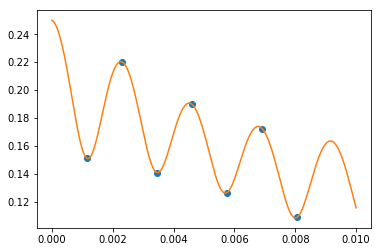

0.2


In [7]:
#teste
rf, rw = set_rho(0.2)

xdata = discrete_timeseries(7)
ydata = gen_GRE(xdata, rf, rw)

fitted_param, pcv = curve_fit(gen_GRE, xdata, ydata, p0=[rf,rw])

x_cont = continuous_timeseries()
y_fit = gen_GRE(x_cont, *fitted_param)

plt.plot(xdata,ydata,'o')
plt.plot(x_cont,y_fit,'-')
plt.show()

ff_calc = calc_fatfrac(fitted_param)
print ff_calc
